# ResNet-56 on CIFAR-10
Implementation based on **He et al., *Deep Residual Learning for Image Recognition*** (arXiv:1512.03385), Section 4.2 (CIFAR-10).

## Key Takeaways from the Paper
- **Degradation problem**: Deeper *plain* networks exhibit *higher training error* than shallower ones — this is not caused by overfitting, but by optimization difficulty.
- **Residual learning**: Stacked layers fit a residual mapping $F(x) = H(x) - x$, and the block outputs $y = F(x, \{W_i\}) + x$. Identity shortcut connections add neither extra parameters nor significant computational complexity.
- **CIFAR-10 architecture** ($32 \times 32$ input with per-pixel mean subtracted): the first layer is a $3 \times 3$ conv (16 filters), followed by 3 stages of $2n$ $3 \times 3$ conv layers on feature maps of sizes $32 \times 32$, $16 \times 16$, and $8 \times 8$ with 16, 32, and 64 filters respectively. Downsampling is performed by convolutions with stride 2. The network ends with global average pooling, a 10-way fully-connected layer, and softmax. Total depth is $6n + 2$ weighted layers; for **ResNet-56**, $n = 9$ (0.85M parameters, reported test error **6.97%**).
- **Shortcuts**: On CIFAR-10, identity shortcuts are used in all cases (**Option A**) — when dimensions increase, the shortcut performs stride-2 subsampling and zero-padding along the channel dimension (0 extra parameters; $3n = 27$ shortcuts total).
- **Training setup**: SGD with momentum 0.9, weight decay $10^{-4}$, mini-batch size 128, initial learning rate 0.1 divided by 10 at 32k and 48k iterations, terminated at 64k iterations (determined on a 45k/5k train/val split), Kaiming (He) initialization, Batch Normalization, and no dropout.
- **Data augmentation**: 4 pixels padded on each side, followed by a random $32 \times 32$ crop and random horizontal flip. Testing evaluates the single view of the original $32 \times 32$ image.

In [1]:
import time, random, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
if device == 'cpu': print('UWAGA: brak GPU! Runtime -> Change runtime type -> GPU, potem zrestartuj sesję.')
torch.backends.cudnn.benchmark = True

# --- Konfiguracja zgodna z artykułem ---
N = 9                       # ResNet-56 = 6*9+2
BATCH = 128
LR, MOMENTUM, WD = 0.1, 0.9, 1e-4
MAX_ITERS = 64_000          # koniec treningu
MILESTONES = (32_000, 48_000)  # lr /= 10
# Dla szybkiego testu na CPU ustaw np. QUICK = False
QUICK = False
if QUICK: MAX_ITERS, MILESTONES = 400, (200, 300)

device: cuda


## Data: 45k/5k Train/Val Split, Per-Pixel Mean Subtraction, and GPU Augmentation
The 50,000 CIFAR-10 training images are split into 45,000 training and 5,000 validation samples. The per-pixel mean image ($3 \times 32 \times 32$) is computed strictly on the 45k training split and subtracted from all splits. Training augmentation (4-pixel zero padding, random $32 \times 32$ crop, random horizontal flip) is vectorized on the GPU for higher throughput.

In [2]:
root = './data'
full = torchvision.datasets.CIFAR10(root, train=True, download=True)
test_raw = torchvision.datasets.CIFAR10(root, train=False, download=True)

# średnia per-piksel (obraz 32x32x3) liczona na zbiorze treningowym (45k)
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(50_000, generator=g).tolist()
train_idx, val_idx = perm[:45_000], perm[45_000:]

x_all = torch.from_numpy(full.data).permute(0,3,1,2).float()/255.   # N,3,32,32
y_all = torch.tensor(full.targets)
mean_img = x_all[train_idx].mean(0, keepdim=True)                  # 1,3,32,32 (per-pixel mean)

x_tr, y_tr = x_all[train_idx]-mean_img, y_all[train_idx]
x_val, y_val = x_all[val_idx]-mean_img, y_all[val_idx]
x_te = torch.from_numpy(test_raw.data).permute(0,3,1,2).float()/255. - mean_img
y_te = torch.tensor(test_raw.targets)

# dane i augmentacja w całości na GPU (znacznie szybciej niż augmentacja na CPU)
x_tr_d, y_tr_d = x_tr.to(device), y_tr.to(device)
AR = torch.arange(32, device=device)

def augment(x):
    # pad 4 px + losowy crop 32x32 + losowe odbicie poziome (osobno dla każdego obrazu)
    B = x.size(0)
    xp = F.pad(x, (4,4,4,4))
    dy = torch.randint(0, 9, (B,), device=device); dx = torch.randint(0, 9, (B,), device=device)
    rows = (dy[:,None] + AR)[:, None, :, None]
    cols = (dx[:,None] + AR)[:, None, None, :]
    out = xp[torch.arange(B, device=device)[:,None,None,None], torch.arange(3, device=device)[None,:,None,None], rows, cols]
    flip = torch.rand(B, device=device) < 0.5
    return torch.where(flip[:,None,None,None], out.flip(3), out)

def train_batches():
    while True:   # kolejne epoki
        perm = torch.randperm(len(x_tr_d), device=device)
        for i in range(0, len(perm) - BATCH + 1, BATCH):   # drop_last
            idx = perm[i:i+BATCH]
            yield augment(x_tr_d[idx]), y_tr_d[idx]

mk = lambda x,y: DataLoader(torch.utils.data.TensorDataset(x,y), 1000)
val_loader, test_loader = mk(x_val,y_val), mk(x_te,y_te)
print(len(x_tr), len(x_val), len(x_te))

45000 5000 10000


## Model Architecture
`BasicBlock` consists of two $3 \times 3$ convolutions with Batch Normalization, ReLU after the first BN, shortcut addition, and ReLU after the addition. Dimension-changing shortcuts use **Option A** (stride-2 subsampling + channel zero-padding, zero extra parameters). Setting `residual=False` produces the exact **Plain-56** counterpart with identical depth, width, and parameter count (0.853M parameters, 56 weighted layers).

In [3]:
class ShortcutA(nn.Module):
    # identity: subsampling stride 2 + zero-padding kanałów (bez parametrów)
    def __init__(self, planes):
        super().__init__(); self.pad = planes//4
    def forward(self, x):
        return F.pad(x[:, :, ::2, ::2], (0,0,0,0,self.pad,self.pad))

class BasicBlock(nn.Module):
    def __init__(self, inp, out, stride, residual=True):
        super().__init__()
        self.conv1 = nn.Conv2d(inp, out, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(out)
        self.conv2 = nn.Conv2d(out, out, 3, 1, 1, bias=False);      self.bn2 = nn.BatchNorm2d(out)
        self.residual = residual
        self.shortcut = nn.Identity() if (stride == 1 and inp == out) else ShortcutA(out)
    def forward(self, x):
        o = F.relu(self.bn1(self.conv1(x)))
        o = self.bn2(self.conv2(o))
        if self.residual: o = o + self.shortcut(x)
        return F.relu(o)

class CifarResNet(nn.Module):
    def __init__(self, n=9, num_classes=10, residual=True):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, 1, 1, bias=False); self.bn1 = nn.BatchNorm2d(16)
        layers, inp = [], 16
        for planes, stride in [(16,1),(32,2),(64,2)]:
            for i in range(n):
                layers.append(BasicBlock(inp, planes, stride if i==0 else 1, residual)); inp = planes
        self.layers = nn.Sequential(*layers)
        self.fc = nn.Linear(64, num_classes)
        for m in self.modules():                       # inicjalizacja He et al. [13]
            if isinstance(m, (nn.Conv2d, nn.Linear)): nn.init.kaiming_normal_(m.weight)
    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.layers(x)
        return self.fc(F.adaptive_avg_pool2d(x,1).flatten(1))   # softmax w CrossEntropyLoss

def resnet56(residual=True): return CifarResNet(9, residual=residual)

model = resnet56()
n_params = sum(p.numel() for p in model.parameters())
n_weighted = sum(isinstance(m,(nn.Conv2d,nn.Linear)) for m in model.modules())
print(f'warstwy z wagami: {n_weighted} (oczekiwane 56), parametry: {n_params/1e6:.3f}M (artykuł: 0.85M)')
assert n_weighted == 56
print(model(torch.randn(2,3,32,32)).shape)

warstwy z wagami: 56 (oczekiwane 56), parametry: 0.853M (artykuł: 0.85M)
torch.Size([2, 10])


## Training Loop
Iteration-based learning rate schedule matching the paper: `lr = 0.1` $\rightarrow$ `0.01` at 32k iterations $\rightarrow$ `0.001` at 48k iterations, stopping at 64k iterations. Automatic Mixed Precision (`fp16`) is enabled on CUDA for faster training on Colab GPU.

In [4]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval(); correct = loss = 0
    for x,y in loader:
        x,y = x.to(device), y.to(device)
        out = model(x); loss += F.cross_entropy(out,y,reduction='sum').item()
        correct += (out.argmax(1)==y).sum().item()
    n = len(loader.dataset); return loss/n, 100*(1-correct/n)   # loss, błąd %

def train(model, max_iters=MAX_ITERS, milestones=MILESTONES, eval_every=500, name='model'):
    model.to(device)
    opt = torch.optim.SGD(model.parameters(), lr=LR, momentum=MOMENTUM, weight_decay=WD)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, list(milestones), 0.1)   # krok = iteracja
    hist = dict(it=[], train_err=[], val_err=[], val_loss=[]); it = 0; run_c = run_n = 0; t0 = time.time()
    use_amp = device == 'cuda'
    scaler = torch.amp.GradScaler(enabled=use_amp)
    model.train()
    while it < max_iters:
        for x,y in train_batches():
            model.train()
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
                out = model(x); loss = F.cross_entropy(out,y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step(); it += 1
            run_c += (out.argmax(1)==y).sum(); run_n += len(y)   # bez synchronizacji GPU w każdej iteracji
            if it % eval_every == 0 or it == max_iters:
                vl, ve = evaluate(model, val_loader)
                hist['it'].append(it); hist['train_err'].append(100*(1-float(run_c)/run_n)); hist['val_err'].append(ve); hist['val_loss'].append(vl)
                print(f'[{name}] it {it:6d} lr {opt.param_groups[0]["lr"]:.4f} train_err {hist["train_err"][-1]:.2f}% val_err {ve:.2f}% ({time.time()-t0:.0f}s)')
                run_c = 0; run_n = 0
            if it >= max_iters: break
    return hist

hist56 = train(model, name='ResNet-56')
torch.save(model.state_dict(), 'resnet56_cifar10.pt')

/tmp/ipykernel_29571/646980145.py:23: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step(); it += 1


[ResNet-56] it    500 lr 0.1000 train_err 76.65% val_err 63.74% (23s)
[ResNet-56] it   1000 lr 0.1000 train_err 57.13% val_err 50.38% (44s)
[ResNet-56] it   1500 lr 0.1000 train_err 43.09% val_err 36.54% (65s)
[ResNet-56] it   2000 lr 0.1000 train_err 32.21% val_err 31.86% (87s)
[ResNet-56] it   2500 lr 0.1000 train_err 26.36% val_err 23.56% (108s)
[ResNet-56] it   3000 lr 0.1000 train_err 22.62% val_err 23.68% (129s)
[ResNet-56] it   3500 lr 0.1000 train_err 20.27% val_err 23.32% (150s)
[ResNet-56] it   4000 lr 0.1000 train_err 18.54% val_err 22.08% (171s)
[ResNet-56] it   4500 lr 0.1000 train_err 17.20% val_err 22.44% (193s)
[ResNet-56] it   5000 lr 0.1000 train_err 16.01% val_err 22.40% (215s)
[ResNet-56] it   5500 lr 0.1000 train_err 14.89% val_err 18.84% (236s)
[ResNet-56] it   6000 lr 0.1000 train_err 14.39% val_err 18.12% (258s)
[ResNet-56] it   6500 lr 0.1000 train_err 13.28% val_err 18.48% (279s)
[ResNet-56] it   7000 lr 0.1000 train_err 13.02% val_err 19.22% (301s)
[ResNet-56

## ResNet-56 Results
Evaluation on the validation (5k) and test (10k) sets using the final model at iteration 64,000, alongside the training and validation error curves.

ResNet-56  val error: 7.08%   TEST error: 7.52%   (artykuł: 6.97%)


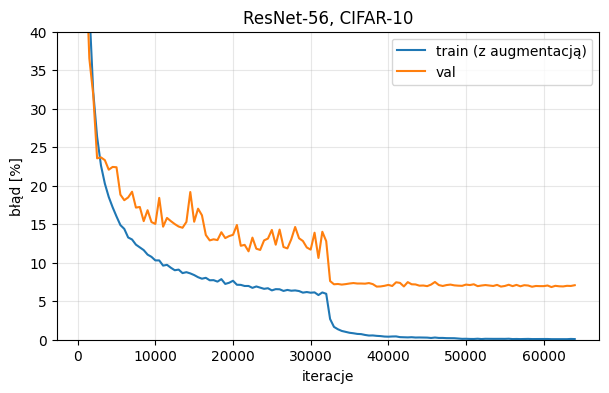

In [5]:
_, test_err = evaluate(model, test_loader)
_, val_err = evaluate(model, val_loader)
print(f'ResNet-56  val error: {val_err:.2f}%   TEST error: {test_err:.2f}%   (artykuł: 6.97%)')

plt.figure(figsize=(7,4))
plt.plot(hist56['it'], hist56['train_err'], label='train (z augmentacją)')
plt.plot(hist56['it'], hist56['val_err'], label='val')
plt.xlabel('iteracje'); plt.ylabel('błąd [%]'); plt.ylim(0,40); plt.grid(alpha=.3); plt.legend(); plt.title('ResNet-56, CIFAR-10')
plt.show()

## Comparison with Plain-56 (Without Residual Connections)
To verify the degradation problem analyzed in the paper (Fig. 6), we train the 56-layer plain counterpart (`residual=False`, removing all 27 identity shortcuts) under the exact same hyperparameters, data split, and training schedule, and compare its learning curves and test error against ResNet-56.

/tmp/ipykernel_29571/646980145.py:23: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step(); it += 1


[Plain-56] it    500 lr 0.1000 train_err 89.35% val_err 88.02% (20s)
[Plain-56] it   1000 lr 0.1000 train_err 87.75% val_err 87.06% (41s)
[Plain-56] it   1500 lr 0.1000 train_err 79.83% val_err 72.82% (61s)
[Plain-56] it   2000 lr 0.1000 train_err 71.57% val_err 68.46% (82s)
[Plain-56] it   2500 lr 0.1000 train_err 67.00% val_err 62.62% (103s)
[Plain-56] it   3000 lr 0.1000 train_err 64.08% val_err 65.10% (123s)
[Plain-56] it   3500 lr 0.1000 train_err 60.78% val_err 61.72% (144s)
[Plain-56] it   4000 lr 0.1000 train_err 58.68% val_err 59.34% (165s)
[Plain-56] it   4500 lr 0.1000 train_err 56.01% val_err 56.00% (185s)
[Plain-56] it   5000 lr 0.1000 train_err 53.51% val_err 53.94% (206s)
[Plain-56] it   5500 lr 0.1000 train_err 51.06% val_err 50.08% (227s)
[Plain-56] it   6000 lr 0.1000 train_err 48.55% val_err 49.30% (247s)
[Plain-56] it   6500 lr 0.1000 train_err 46.38% val_err 46.10% (268s)
[Plain-56] it   7000 lr 0.1000 train_err 43.82% val_err 45.62% (288s)
[Plain-56] it   7500 lr 

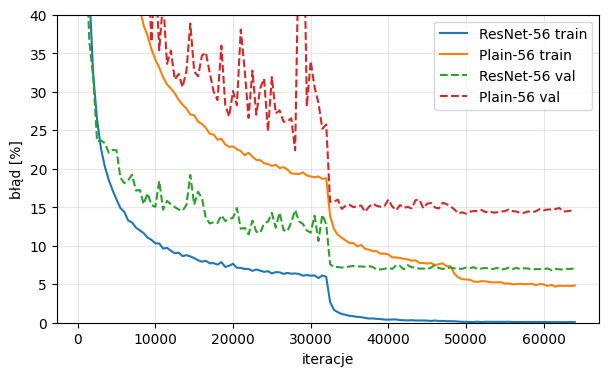

In [6]:
RUN_PLAIN = True
if RUN_PLAIN:
    plain = resnet56(residual=False)
    hist_plain = train(plain, name='Plain-56')
    print('Plain-56 test error: %.2f%%' % evaluate(plain, test_loader)[1])
    plt.figure(figsize=(7,4))
    plt.plot(hist56['it'], hist56['train_err'], label='ResNet-56 train'); plt.plot(hist_plain['it'], hist_plain['train_err'], label='Plain-56 train')
    plt.plot(hist56['it'], hist56['val_err'], '--', label='ResNet-56 val'); plt.plot(hist_plain['it'], hist_plain['val_err'], '--', label='Plain-56 val')
    plt.ylim(0,40); plt.legend(); plt.grid(alpha=.3); plt.xlabel('iteracje'); plt.ylabel('błąd [%]'); plt.show()

## Conclusions
- **Architecture faithfulness**: The implemented ResNet-56 has exactly **56 weighted layers** and **0.853M parameters** (paper: 0.85M), using Option A identity shortcuts, Kaiming initialization, BatchNorm, no dropout, and the paper's exact augmentation and 64k-iteration LR schedule.
- **ResNet-56 performance**: At 64k iterations, ResNet-56 achieved **0.08%** training error, **7.08%** validation error, and **7.52%** test error (paper: **6.97%**). The +0.55 p.p. gap is primarily explained by training on 45k images (holding out 5k for validation, whereas Table 6 in the paper trains on all 50k images) and single-seed variance.
- **Degradation problem confirmed (ResNet-56 vs. Plain-56)**: Removing the 27 identity shortcuts while keeping depth, width, and parameter count identical caused training error to increase from **0.08%** to **4.85%** and test error to more than double from **7.52%** to **15.50%**. Because Plain-56 fails to optimize even on the training set, this confirms that the degradation is an optimization difficulty rather than overfitting, and that parameter-free residual connections effectively resolve it.